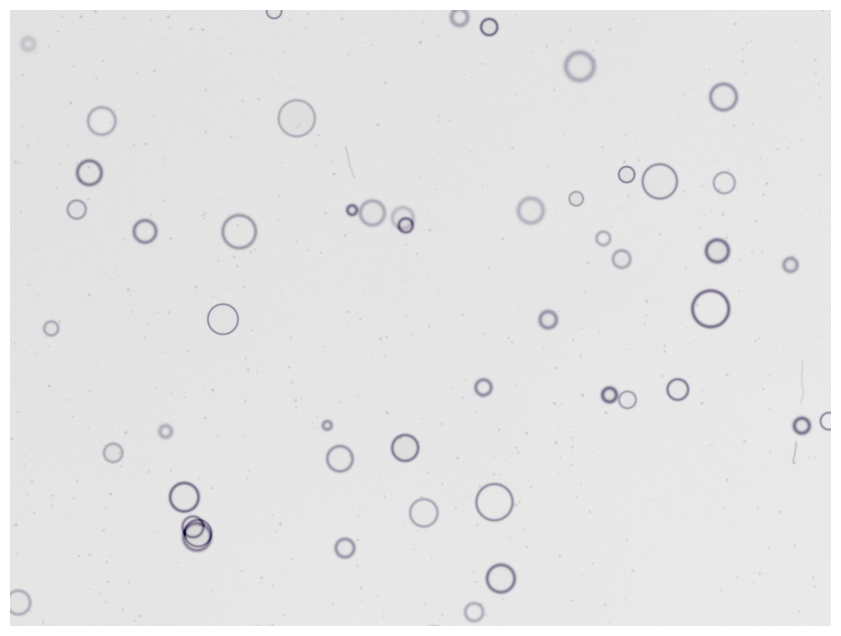

Current folder: C:\Users\User\Desktop\img generate
CSV exists: True
Files: ['.ipynb_checkpoints', 'Circles.ipynb', 'do-to.txt', 'generate.ipynb', 'generate.py', 'main_code.ipynb', 'synthetic_radon.png', 'synthetic_radon_truth.csv', '__pycache__']


In [2]:
from generate import generate
import csv
from pathlib import Path
import numpy as np
from scipy.ndimage import gaussian_filter
from PIL import Image
import os
import matplotlib.pyplot as plt
import cv2 as cv
import sys
import pandas as pd
from pandas.errors import EmptyDataError

In [3]:
OUTPUT_IMG_PATH = Path.home() / "Desktop" / "RADON_images"
OUTPUT_CSV_PATH = Path.home() / "Desktop" / "RADON_tables"


# Generation of images function
def generate_img(nr_of_img, nr_tracks):
    
    output_img = Path(OUTPUT_IMG_PATH)
    output_csv = Path(OUTPUT_CSV_PATH)

    # Create the folders, exist_ok=True avoids errors if they already exist
    output_img.mkdir(parents=True, exist_ok=True)
    output_csv.mkdir(parents=True, exist_ok=True)

    # Remove previous images and csv in the folders
    for item in output_img.iterdir():
        if item.is_file():
            item.unlink()
    for item in output_csv.iterdir():
        if item.is_file():
            item.unlink()

    # loop to generate the required nr of img. Seed changes each time.
    for i in range(nr_of_img):
        
        F_output = output_img / f"synthetic_radon_{i}.png"
        F_truth = output_csv / f"synthetic_radon_truth_{i}.csv"

        IMG_pixel = (800, 1000)   #dimentions can be changed
        seed = i

        generate(
            output=F_output,
            truth=F_truth,
            shape=IMG_pixel,
            n_tracks=nr_tracks,
            seed=seed,
        )

    # Test if enough images were made
    image_count = sum(1 for item in output_img.iterdir() if item.is_file())
    if image_count != nr_of_img:
        print(f"Error, {image_count} files when there should be {nr_of_img}")


In [4]:
OUTPUT_IMG_PATH = Path.home() / "Desktop" / "RADON_images"
OUTPUT_DETECTED_PATH = Path.home() / "Desktop" / "RADON_detected"


# Detection function of circles in generated images
def detection(nr_img_detect, Hough_param1, Hough_param2):
    input_img_dir = Path(OUTPUT_IMG_PATH)
    det_csv = Path(OUTPUT_DETECTED_PATH)

    # Create the RADON_detected folder
    det_csv.mkdir(parents=True, exist_ok=True)

    # Remove previous csv in folder
    for item in det_csv.iterdir():
        if item.is_file():
            item.unlink()
    #detection of circles loop
    for j in range(nr_img_detect):
        specs = []
        img_path = input_img_dir / f"synthetic_radon_{j}.png"
        img = cv.imread(str(img_path), cv.IMREAD_COLOR)
        #test if there is an image
        if img is None:
            print(f"Error opening image: {img_path}")
            continue

        gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
        gray = cv.blur(gray, (4, 4))
        #using Hough Transform
        circles = cv.HoughCircles(
            gray,
            cv.HOUGH_GRADIENT,
            1,
            minDist=7,
            param1=Hough_param1,
            param2=Hough_param2,
            minRadius=7,
            maxRadius=31,
        )
        
        out_csv_path = det_csv / f"data{j}.csv"
        nr = 0
        #recording the found circle  data (x and y coordinate of te centre, and the radius length)
        if circles is not None:
            circles_rounded = np.uint16(np.around(circles))
            for i in circles_rounded[0, :]:
                center = (int(i[0]), int(i[1]))
                radius = int(i[2])
                cv.circle(img, center, 1, (0, 100, 100), 3)
                cv.circle(img, center, radius, (255, 0, 255), 3)
                specs.append((center[0], center[1], radius))
                nr += 1

        #save this data in the RADON_detected folder as csv
        with open(out_csv_path, "w", newline="") as file:
            writer = csv.writer(file)
            writer.writerow(["x_px", "y_px", "radius_px"])
            if specs:
                writer.writerows(specs)

        print(f"data{j}    detected: {nr}")
    #test if all files went through detection
    det_count = sum(1 for item in det_csv.iterdir() if item.is_file())
    if det_count != nr_img_detect:
        print(f"Error, {det_count} files when there should be {nr_of_img_detect if False else nr_img_detect}")

In [5]:
OUTPUT_CSV_PATH = Path.home() / "Desktop" / "RADON_tables"
OUTPUT_DETECTED_PATH = Path.home() / "Desktop" / "RADON_detected"
OUTPUT_DIFFS_PATH = Path.home() / "Desktop" / "RADON_diffs"

# Function to compare the detected circle data to the real data
def compare(nr_data_compare):
    global x_diff, y_diff, r_diff

    real_dir = Path(OUTPUT_CSV_PATH)
    det_dir = Path(OUTPUT_DETECTED_PATH)
    diffs_dir = Path(OUTPUT_DIFFS_PATH)

    # Create the RADON_diffs folder
    diffs_dir.mkdir(parents=True, exist_ok=True)

    for i in range(nr_data_compare):
        # Get the x/y center coordinates and radius values from the real, generated data. Save in an array called rd
        real_path = real_dir / f"synthetic_radon_truth_{i}.csv"
        rd = pd.read_csv(real_path)
        rd = rd[["x_px", "y_px", "radius_px"]]
        rd = rd.to_numpy()
        rd = rd[np.lexsort((rd[:, 1], rd[:, 0]))]

        # # Get the x/y center coordinates and radius values from the detected data. Save in an array called dd. Taking into account empty csv-s.
        det_path = det_dir / f"data{i}.csv"
        try:
            det_data_df = pd.read_csv(det_path)
            if det_data_df.empty:
                dd = np.empty((0, 3))
            else:
                dd = det_data_df[["x_px", "y_px", "radius_px"]].to_numpy()
                dd = dd[np.lexsort((dd[:, 1], dd[:, 0]))]
        except EmptyDataError:
            dd = np.empty((0, 3))

        found_id_det = []
        found_id_real = []
        diff_rows = []

        # Loop to match detected circles to real ones. Allows 5px difference. 
        for id_det in range(len(dd)):
            for id_real in range(len(rd)):
                if id_real in found_id_real:
                    continue

                x_diff = dd[id_det][0] - rd[id_real][0]
                y_diff = dd[id_det][1] - rd[id_real][1]
                r_diff = dd[id_det][2] - rd[id_real][2]

                if abs(x_diff) <= 5 and abs(y_diff) <= 5:
                    found_id_det.append(id_det)
                    found_id_real.append(id_real)
                    diff_rows.append([x_diff, y_diff, r_diff])
                    break

        # Write matched circle center and radius differences to RADON_diffs
        out_path = diffs_dir / f"data{i}.csv"
        with open(out_path, "w", newline="") as file:
            writer = csv.writer(file)
            writer.writerow(["x_diff", "y_diff", "r_diff"])
            writer.writerows(diff_rows)

        # Identify unmatched circles ("Unfound") and extras in detection ("Extras in detection")
        real_unfound = np.delete(rd, found_id_real, axis=0)
        det_wrong = np.delete(dd, found_id_det, axis=0)

        print(
            f"In image {i}:",
            "Extras in detection:",
            len(det_wrong),
            "Unfound:",
            len(real_unfound),
        )

In [21]:
generate_img(nr_of_img=100, nr_tracks=2)
detection(nr_img_detect=100, Hough_param1=10 , Hough_param2= 30)
compare(nr_data_compare=100)



data0    detected: 2
data1    detected: 2
data2    detected: 2
data3    detected: 2
data4    detected: 2
data5    detected: 2
data6    detected: 2
data7    detected: 2
data8    detected: 2
data9    detected: 2
data10    detected: 2
data11    detected: 2
data12    detected: 2
data13    detected: 2
data14    detected: 1
data15    detected: 2
data16    detected: 2
data17    detected: 2
data18    detected: 2
data19    detected: 2
data20    detected: 2
data21    detected: 2
data22    detected: 2
data23    detected: 2
data24    detected: 2
data25    detected: 2
data26    detected: 2
data27    detected: 2
data28    detected: 2
data29    detected: 2
data30    detected: 2
data31    detected: 2
data32    detected: 2
data33    detected: 1
data34    detected: 2
data35    detected: 2
data36    detected: 2
data37    detected: 2
data38    detected: 2
data39    detected: 2
data40    detected: 2
data41    detected: 2
data42    detected: 2
data43    detected: 2
data44    detected: 2
data45    detected: 

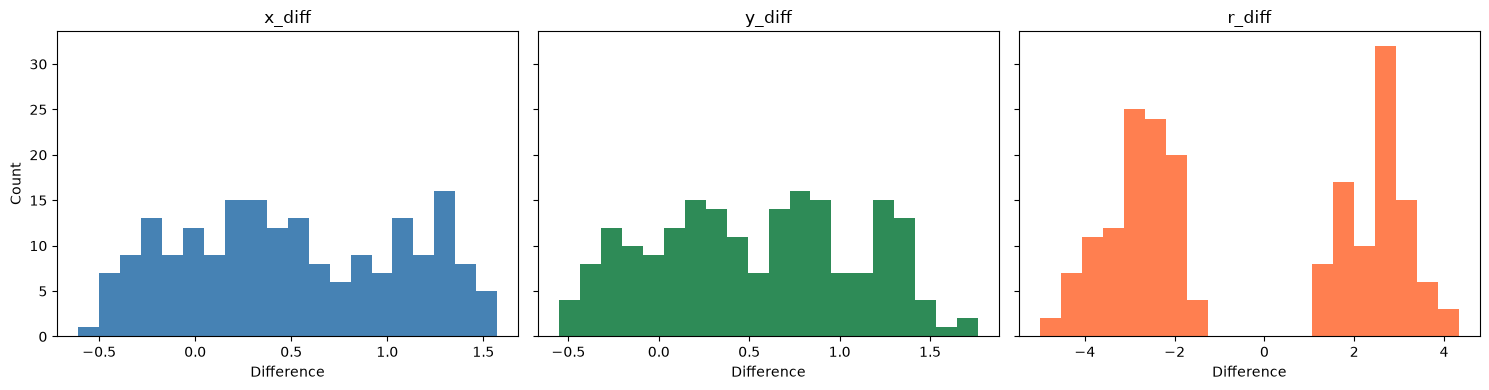

For x: Mean:  0.5043406342096645 Std:  0.5722399941789196
For y: Mean:  0.5410378957015805 Std:  0.5609340179142454
For r: Mean:  -0.3424123372101811 Std:  2.779961584236969


In [6]:
OUTPUT_DIFFS_PATH = Path.home() / "Desktop" / "RADON_diffs"

# Convert to Path and ensure the directory exists from the start
diffs_dir = Path(OUTPUT_DIFFS_PATH)
diffs_dir.mkdir(parents=True, exist_ok=True)

# Count how many diff CSV files are in the folder
num_files = sum(1 for entry in diffs_dir.iterdir() if entry.is_file())

x = np.array([])
y = np.array([])
r = np.array([])

for i in range(num_files):
    csv_path = diffs_dir / f"data{i}.csv"
    if not csv_path.exists():
        continue

    diffs = pd.read_csv(csv_path)
    if not diffs.empty:
        x = np.append(x, diffs["x_diff"].to_numpy())
        y = np.append(y, diffs["y_diff"].to_numpy())
        r = np.append(r, diffs["r_diff"].to_numpy())

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

datasets = [x, y, r]
titles = ["x_diff", "y_diff", "r_diff"]
colors = ["steelblue", "seagreen", "coral"]

for ax, data, title, color in zip(axes, datasets, titles, colors):
    ax.hist(data, bins=20, color=color)
    ax.set_title(title)
    ax.set_xlabel("Difference")

axes[0].set_ylabel("Count")
plt.tight_layout()
plt.show()


mean_x=np.mean(x)
std_x=np.std(x)

mean_y=np.mean(y)
std_y=np.std(y)

mean_r=np.mean(r)
std_r=np.std(r)

print("For diffs in x: Mean: ",mean_x,"Std: ", std_x)
print("For y: Mean: ",mean_y,"Std: ", std_y)
print("For r: Mean: ",mean_r,"Std: ", std_r)